# Road Conditions and Crash Injury Severity in Minnesota

**Research Question:** Are crashes on dry roads more likely to result in injuries or fatalities than crashes on snowy or icy roads in Minnesota?

I use all months from 2020 through 2025, with two groups:

- **Dry:** crashes on dry roads.
- **Snow/Ice:** crashes recorded as Snow or Ice/Frost.

My main measure is the percentage of reported crashes involving at least one injury or death.

## Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

In [2]:
# These are three separate MNCrash exports filtered by road surface.
source_files = {
    "Dry": "Collision-Export-261120231043.zip",
    "Snow": "Collision-Export-261120231454.zip",
    "Ice/Frost": "Collision-Export-261120231342.zip",
}
parts = []
file_checks = []
for surface, name in source_files.items():
    path = next((p for p in [Path("data") / name, Path(name)] if p.exists()), None)
    if path is None:
        raise FileNotFoundError(f"Missing {name}: put it in data/ or beside this notebook")
    with zipfile.ZipFile(path) as archive:
        csv_name = next(x for x in archive.namelist() if x.lower().endswith(".csv"))
        with archive.open(csv_name) as stream:
            exported_rows = sum(1 for _ in stream) - 1
    part = pd.read_csv(path, compression="zip", dtype="string",
                       on_bad_lines="skip", low_memory=False)
    part["Road_Surface"] = surface  # Original filter used for the CSV export.
    part["Surface_Group"] = "Dry" if surface == "Dry" else "Snow/Ice"
    file_checks.append({"Surface": surface, "Exported_Rows": exported_rows,
                        "Loaded_Rows": len(part),
                        "Malformed_Rows_Skipped": exported_rows - len(part)})
    parts.append(part)
raw = pd.concat(parts, ignore_index=True)
display(pd.DataFrame(file_checks))
print("Loaded rows:", len(raw))
print("Columns:", len(raw.columns))

,Surface,Exported_Rows,Loaded_Rows,Malformed_Rows_Skipped
0,Dry,267683,267681,2
1,Snow,33610,33609,1
2,Ice/Frost,33627,33626,1


Loaded rows: 334916
Columns: 19


In [3]:
raw.head()

,ACN,Local ID,Crash Date,Roadway,City,Township,County,Tribal Nation,Agency,Crash Severity,Number of Fatalities,Number of Injuries,Latitude,Longitude,Alcohol Related,Distraction Related,Speed Related,Road_Surface,Surface_Group
0,162370060,25005664,6/26/2025 5:58:00 PM,NICOLLET AVE S at 82ND ST,Bloomington,<NA>,Hennepin,<NA>,Bloomington Police Dept,Possible Injury Crash,0,2,44.85522274,-93.27832020,No,No,No,Dry,Dry
1,190340041,20001796,2/24/2020 4:07:00 PM,9TH ST NE at 3RD AVE NE,Buffalo,<NA>,Wright,<NA>,Buffalo Police Dept,Property Damage Only Crash,0,0,45.18092692,-93.87195584,No,No,No,Dry,Dry
2,191950086,SP23003143,11/9/2023 1:00:00 AM,4TH ST,Saint Paul Park,<NA>,Washington,<NA>,Gibbon Police Dept,<NA>,0,0,44.84710027,-92.99642569,No,No,No,Dry,Dry
3,192290065,20012580,5/11/2020 5:00:00 PM,RIVER RD at HONEYTREE DR,Delano,<NA>,Wright,<NA>,Wright County Sheriff,Property Damage Only Crash,0,0,45.03245960,-93.79045155,No,No,Yes,Dry,Dry
4,192950023,MCSO20000574,2/8/2020 4:52:00 AM,MNTH 22,<NA>,Litchfield,Meeker,<NA>,Meeker County Sheriff,Suspected Minor Injury Crash,0,1,45.08427396,-94.51246911,No,Yes,No,Dry,Dry


In [4]:
raw.dtypes

ACN                     string
Local ID                string
Crash Date              string
Roadway                 string
City                    string
Township                string
County                  string
Tribal Nation           string
Agency                  string
Crash Severity          string
Number of Fatalities    string
Number of Injuries      string
Latitude                string
Longitude               string
Alcohol Related         string
Distraction Related     string
Speed Related           string
Road_Surface               str
Surface_Group              str
dtype: object

## 1. Provenance & scope

Data was collected from the Minnesota MNCrash Public Portal. Police report collisions, and data is used by the state to inform traffic policing, infrastructure development and safety education in order to reduce fatalities and severe injuries.

Three CSVs were extracted, based on Road Surface conditions. These conditions were dry, snow and ice/frost. The data includes reported collisions between 01/01/2020 and 31/12/2025. After loading there were 334,916 records and after cleaning 325,259 records.

Each row represents a single reported collision. The Road Surface condition has not been included as a field in the original CSVs. Therefore, each CSV was named according to the condition it was filtered on. Snow and Ice/Frost were grouped together as Snow/Ice.

This data represents reported collisions on different types of road surfaces in Minnesota between 2020-2025. Findings may not generalise to unreported collisions, different states and different timeframes. Data has not been provided for collisions on wet and slush road surfaces.

This data can be used to compare the percentage of injuries/deaths in reported collisions on different road surfaces. However, we cannot determine what road surface carries the highest risk of collision per distance travelled, as distance travelled is not present in the data.

## 2. Structure & quality

In [5]:
# Key variables and their starting types.
key_columns = ["ACN", "Crash Date", "Surface_Group", "Crash Severity",
               "Number of Injuries", "Number of Fatalities", "County"]
display(raw[key_columns].dtypes)
print("All columns:", raw.columns.tolist())

ACN                     string
Crash Date              string
Surface_Group              str
Crash Severity          string
Number of Injuries      string
Number of Fatalities    string
County                  string
dtype: object

All columns: ['ACN', 'Local ID', 'Crash Date', 'Roadway', 'City', 'Township', 'County', 'Tribal Nation', 'Agency', 'Crash Severity', 'Number of Fatalities', 'Number of Injuries', 'Latitude', 'Longitude', 'Alcohol Related', 'Distraction Related', 'Speed Related', 'Road_Surface', 'Surface_Group']


Road condition and crash severity are categories. I will convert the date and injury counts before comparing the two groups.

In [6]:
# Missing values in the most important original columns.
display(raw[key_columns].isna().sum().to_frame("Missing Values"))

,Missing Values
ACN,0
Crash Date,0
Surface_Group,0
Crash Severity,9657
Number of Injuries,0
Number of Fatalities,0
County,0


Some crashes do not have a recorded severity. I will not count these as crashes without injury, because their outcome is unknown.

In [7]:
# Check duplicates and the outcome categories for our TWO road-condition groups.
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated ACN IDs:", raw["ACN"].duplicated().sum())
print("Missing ACN IDs:", raw["ACN"].isna().sum())
display(pd.crosstab(raw["Surface_Group"], raw["Crash Severity"], dropna=False))

Exact duplicate rows: 0
Repeated ACN IDs: 0
Missing ACN IDs: 0


Crash Severity,Fatal Crash,Possible Injury Crash,Property Damage Only Crash,Suspected Minor Injury Crash,Suspected Serious Injury Crash,<NA>
Surface_Group,,,,,,
Dry,1843,39981,181707,28949,7600,7601
Snow/Ice,168,7272,52888,4166,685,2056


ACN is the crash identifier, so I checked it across all three exports. This prevents counting the same reported crash twice if export groups overlap.

In [8]:
# Convert variables into useful types.
raw["Crash_Date"] = pd.to_datetime(
    raw["Crash Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
)
raw["Injuries"] = pd.to_numeric(raw["Number of Injuries"], errors="coerce")
raw["Fatalities"] = pd.to_numeric(raw["Number of Fatalities"], errors="coerce")
print("Invalid dates:", raw["Crash_Date"].isna().sum())
print("Invalid injury counts:", raw["Injuries"].isna().sum())
print("Invalid fatality counts:", raw["Fatalities"].isna().sum())
print("Negative injury or fatality counts:",
      ((raw["Injuries"] < 0) | (raw["Fatalities"] < 0)).sum())
print("Date range:", raw["Crash_Date"].min(), "to", raw["Crash_Date"].max())

Invalid dates: 0
Invalid injury counts: 0
Invalid fatality counts: 0
Negative injury or fatality counts: 0
Date range: 2020-01-01 00:00:00 to 2025-12-31 23:52:00


The downloaded records cover 2020–2025. I will use every month in all six years, rather than selecting only winter records.

In [9]:
# Keep all years and months in the three original files.
# Remove only records for which the outcome or crash identity cannot be trusted.
valid_severities = [
    "Property Damage Only Crash", "Possible Injury Crash",
    "Suspected Minor Injury Crash", "Suspected Serious Injury Crash", "Fatal Crash"
]
valid = (
    raw["ACN"].notna() & raw["Crash_Date"].notna()
    & raw["Crash Severity"].isin(valid_severities)
    & raw["Injuries"].notna() & raw["Fatalities"].notna()
    & (raw["Injuries"] >= 0) & (raw["Fatalities"] >= 0)
)
df = raw.loc[valid].drop_duplicates(subset="ACN").copy()
df["Year"] = df["Crash_Date"].dt.year
df["Month"] = df["Crash_Date"].dt.month
df["Injury_or_Death"] = (df["Injuries"] > 0) | (df["Fatalities"] > 0)
# Both groups were assigned from the actual MNCrash CSV export filters.
surface_order = ["Dry", "Snow/Ice"]

print("Rows loaded:", len(raw))
print("Rows excluded during cleaning:", len(raw) - len(df))
print("Clean rows (2020–2025, all months):", len(df))
print("Unique crash IDs:", df["ACN"].nunique())
display(df.groupby("Surface_Group").size().reindex(surface_order).rename("Crashes"))

Rows loaded: 334916
Rows excluded during cleaning: 9657
Clean rows (2020–2025, all months): 325259
Unique crash IDs: 325259


Surface_Group
Dry         260080
Snow/Ice     65179
Name: Crashes, dtype: int64

After cleaning, the dataset contains 325,259 reported crashes from 2020–2025, all months. It combines the Dry export with the Snow and Ice/Frost exports. I excluded records with missing or invalid outcomes rather than counting them as injury-free.

In [10]:
# Check whether the injury counts agree with the recorded severity.
severity_has_injury = df["Crash Severity"] != "Property Damage Only Crash"
print("Severity and injury-count disagreements:",
      (severity_has_injury != df["Injury_or_Death"]).sum())
display(df[["ACN", "Crash_Date", "Surface_Group", "Crash Severity",
            "Injuries", "Fatalities", "Injury_or_Death"]].head())

Severity and injury-count disagreements: 0


,ACN,Crash_Date,Surface_Group,Crash Severity,Injuries,Fatalities,Injury_or_Death
0,162370060,2025-06-26 17:58:00,Dry,Possible Injury Crash,2,0,True
1,190340041,2020-02-24 16:07:00,Dry,Property Damage Only Crash,0,0,False
3,192290065,2020-05-11 17:00:00,Dry,Property Damage Only Crash,0,0,False
4,192950023,2020-02-08 04:52:00,Dry,Suspected Minor Injury Crash,1,0,True
5,193100026,2020-09-18 16:10:00,Dry,Possible Injury Crash,2,0,True


The injury/fatality counts and severity labels agree in the cleaned records. I will use the counts to define whether each crash involved an injury or death.

In [11]:
# Look at the two groups and related crash report fields.
for col in ["Surface_Group", "Crash Severity", "Speed Related",
            "Alcohol Related", "Distraction Related"]:
    print("\n", col)
    display(df[col].value_counts(dropna=False))


 Surface_Group


Surface_Group
Dry         260080
Snow/Ice     65179
Name: count, dtype: int64


 Crash Severity


Crash Severity
Property Damage Only Crash        234595
Possible Injury Crash              47253
Suspected Minor Injury Crash       33115
Suspected Serious Injury Crash      8285
Fatal Crash                         2011
Name: count, dtype: int64[pyarrow]


 Speed Related


Speed Related
No     276996
Yes     48263
Name: count, dtype: int64[pyarrow]


 Alcohol Related


Alcohol Related
No     305638
Yes     19621
Name: count, dtype: int64[pyarrow]


 Distraction Related


Distraction Related
No     295491
Yes     29768
Name: count, dtype: int64[pyarrow]

These additional flags might help explain differences between groups, but they are based on crash reports. They are not direct measures of actual driving speed or driver behavior in every crash.

## 3. Distributions

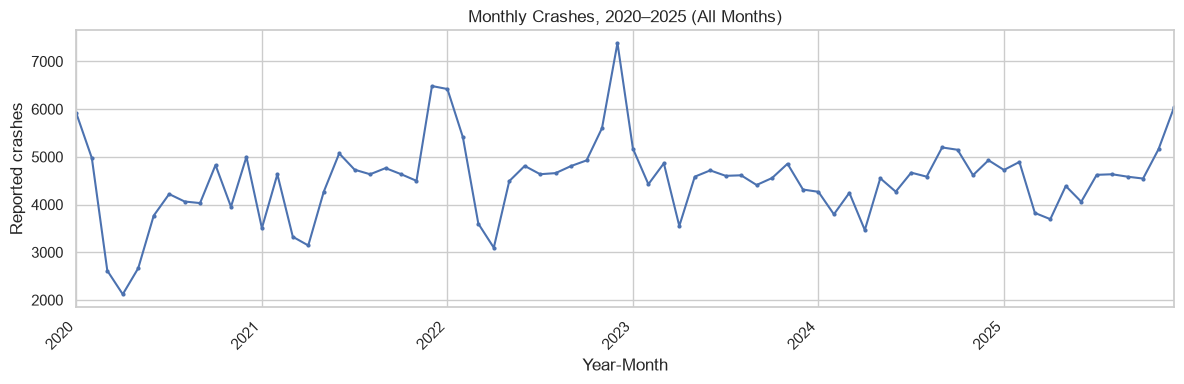

In [12]:
# Monthly crash counts across all six years.
monthly_counts = df.groupby(df["Crash_Date"].dt.to_period("M")).size().sort_index()
ax = monthly_counts.plot(figsize=(12, 4), marker="o", markersize=2)
ax.set(xlabel="Year-Month", ylabel="Reported crashes",
       title="Monthly Crashes, 2020–2025 (All Months)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The total number of reported crashes changes over time. This chart includes all months, so I can see the overall pattern instead of looking only at winter.

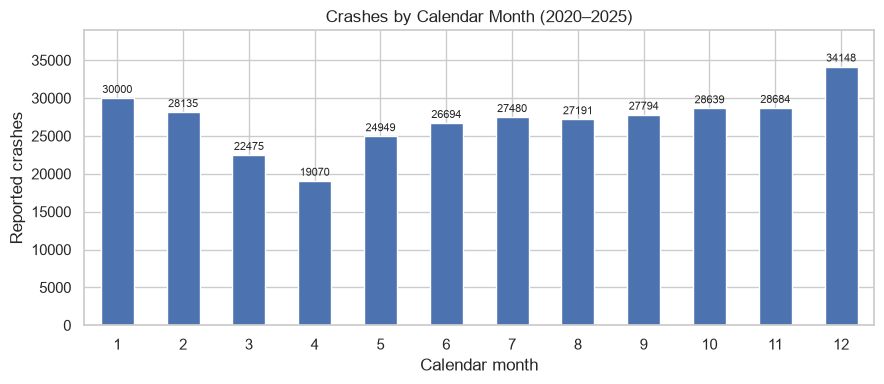

In [13]:
# Total crashes by calendar month, pooled across all six years.
month_counts = df.groupby("Month").size().reindex(range(1, 13), fill_value=0)
ax = month_counts.plot(kind="bar", figsize=(9, 4), rot=0)
ax.bar_label(ax.containers[0], padding=2, fontsize=8)
ax.set(xlabel="Calendar month", ylabel="Reported crashes",
       title="Crashes by Calendar Month (2020–2025)")
ax.margins(y=0.14)
plt.tight_layout()
plt.show()

Crash counts vary by month. This chart shows when more crashes were reported, but it does not tell us which road condition has a higher injury rate.

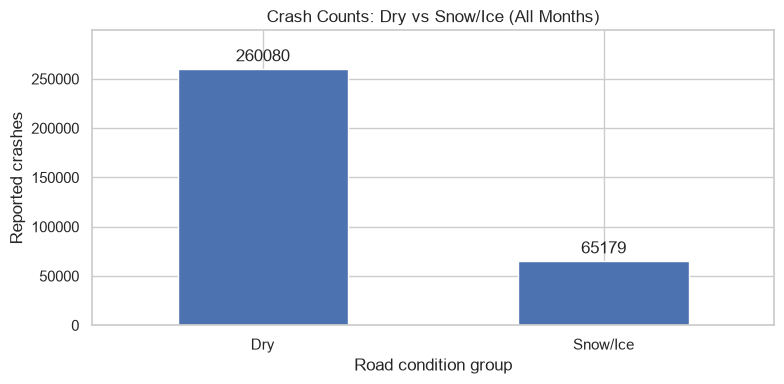

In [14]:
# Crash counts for our TWO road-condition groups.
surface_counts = df["Surface_Group"].value_counts().reindex(surface_order)
ax = surface_counts.plot(kind="bar", figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel="Road condition group", ylabel="Reported crashes",
       title="Crash Counts: Dry vs Snow/Ice (All Months)")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

Dry roads have more reported crashes than Snow/Ice roads. However, this chart only shows the number of crashes, not how often those crashes result in injuries or fatalities.

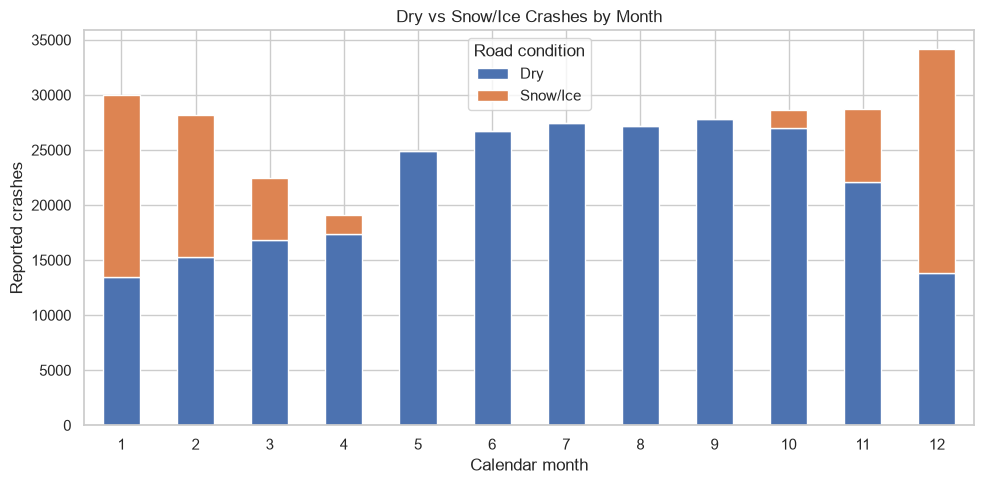

Road-condition percentages within each month:


Surface_Group,Dry,Snow/Ice
Month,,
1,45.0,55.0
2,54.4,45.6
3,74.8,25.2
4,91.2,8.8
5,100.0,0.0
6,100.0,0.0
7,100.0,0.0
8,100.0,0.0
9,100.0,0.0


In [15]:
# Compare the two road-condition groups across calendar months.
month_surface = pd.crosstab(df["Month"], df["Surface_Group"]).reindex(
    index=range(1, 13), columns=surface_order, fill_value=0
)
ax = month_surface.plot(kind="bar", stacked=True, figsize=(10, 5), rot=0)
ax.set(xlabel="Calendar month", ylabel="Reported crashes",
       title="Dry vs Snow/Ice Crashes by Month")
plt.legend(title="Road condition")
plt.tight_layout()
plt.show()
print("Road-condition percentages within each month:")
display((month_surface.div(month_surface.sum(axis=1), axis=0) * 100).round(1))

Snow/Ice crashes mostly happen in colder months. Dry crashes occur year-round. This seasonal difference matters when comparing injury percentages.

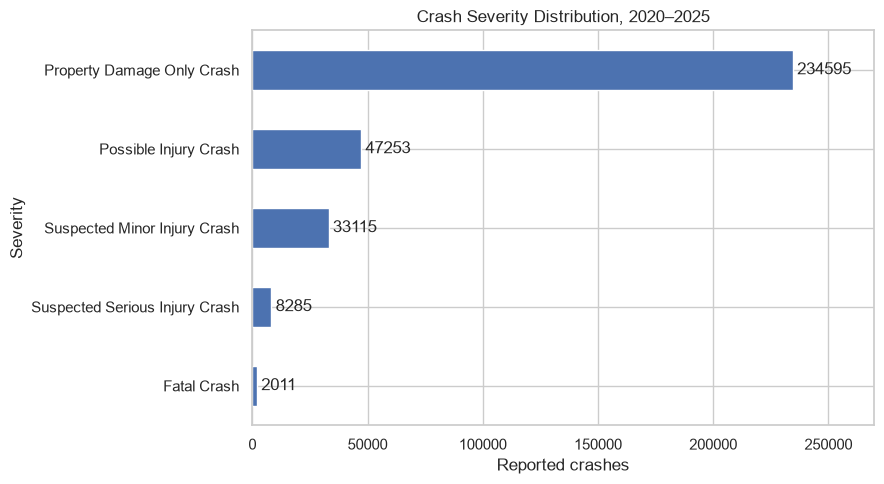

In [16]:
# Crash severity distribution.
severity_order = ["Property Damage Only Crash", "Possible Injury Crash",
                  "Suspected Minor Injury Crash", "Suspected Serious Injury Crash",
                  "Fatal Crash"]
severity_counts = df["Crash Severity"].value_counts().reindex(severity_order)
ax = severity_counts.sort_values().plot(kind="barh", figsize=(9, 5))
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel="Reported crashes", ylabel="Severity",
       title="Crash Severity Distribution, 2020–2025")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Most reported crashes were property-damage-only. Fatal crashes made up a much smaller share of the records.

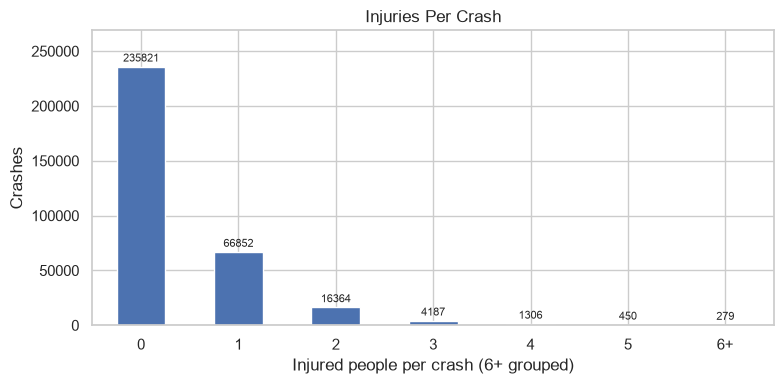

count    325259.0
mean     0.373699
std      0.725768
min           0.0
25%           0.0
50%           0.0
75%           1.0
max          26.0
Name: Injuries, dtype: Float64

In [17]:
# Number of people injured in each crash (group values of 6 or more together).
injury_counts = df["Injuries"].clip(upper=6).value_counts().sort_index()
injury_counts.index = [str(int(i)) if i < 6 else "6+" for i in injury_counts.index]
ax = injury_counts.plot(kind="bar", figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0], padding=2, fontsize=8)
ax.set(xlabel="Injured people per crash (6+ grouped)", ylabel="Crashes",
       title="Injuries Per Crash")
ax.margins(y=0.14)
plt.tight_layout()
plt.show()
display(df["Injuries"].describe())

Most crashes have zero reported injuries. The distribution is right-skewed because some crashes involve multiple injured people.

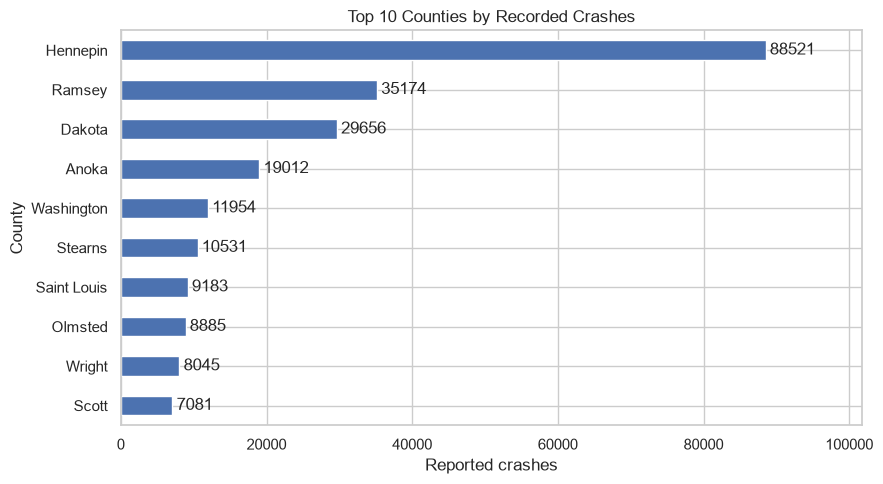

In [18]:
# Counties with the most crash records in these two groups.
county_counts = df["County"].value_counts().head(10).sort_values()
ax = county_counts.plot(kind="barh", figsize=(9, 5))
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel="Reported crashes", ylabel="County",
       title="Top 10 Counties by Recorded Crashes")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Some counties have many more reported crashes than others. This reflects location and traffic exposure as well as crash reporting, not just road-surface risk.

## 4. Relationships

**Question 1: Are crashes on Dry roads more likely to involve injury or death than crashes on Snow/Ice roads?**

,Crashes,Injury_or_Death_Crashes,Rate,Rate_Percent
Surface_Group,,,,
Dry,260080,78373,0.301,30.134
Snow/Ice,65179,12291,0.189,18.857


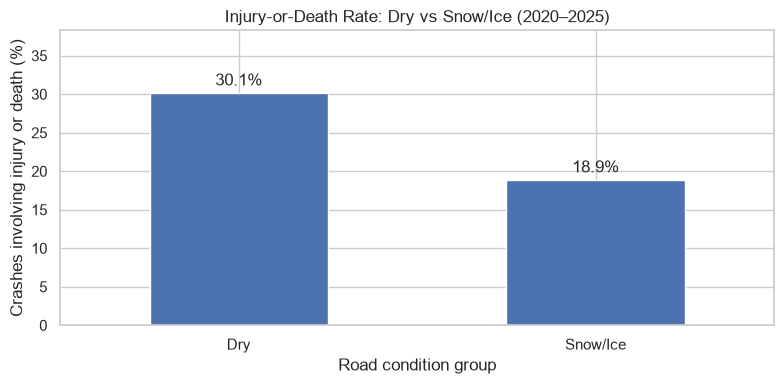

In [19]:
# Main EDA comparison: TWO road-condition groups, using all months.
surface_rates = df.groupby("Surface_Group")["Injury_or_Death"].agg(
    Crashes="size", Injury_or_Death_Crashes="sum", Rate="mean"
).reindex(surface_order)
surface_rates["Rate_Percent"] = surface_rates["Rate"] * 100
display(surface_rates.round(3))

ax = surface_rates["Rate_Percent"].plot(kind="bar", figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(xlabel="Road condition group", ylabel="Crashes involving injury or death (%)",
       title="Injury-or-Death Rate: Dry vs Snow/Ice (2020–2025)")
ax.set_ylim(0, surface_rates["Rate_Percent"].max() * 1.27)
plt.tight_layout()
plt.show()

In these reported crashes, Dry has a higher injury-or-death percentage than the combined Snow/Ice group. This comparison does not show the chance of getting into a crash while driving on either surface.

**Question 2: Is the difference between Dry and Snow/Ice similar each year?**

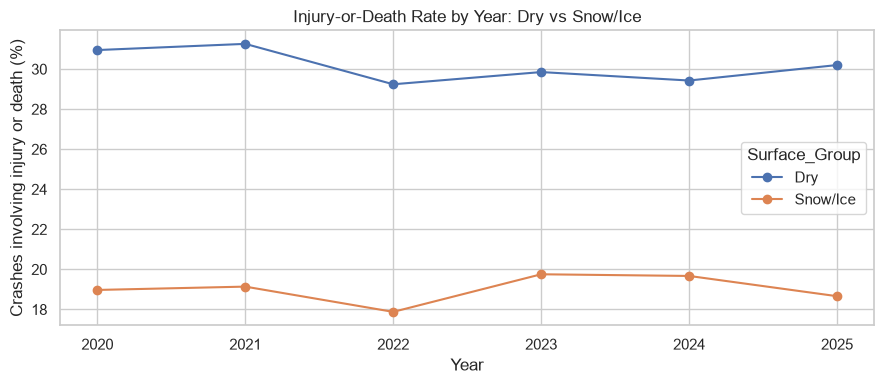

Surface_Group,Dry,Snow/Ice
Year,,
2020,31.0,19.0
2021,31.3,19.1
2022,29.2,17.9
2023,29.9,19.8
2024,29.4,19.7
2025,30.2,18.7


In [20]:
# Injury-or-death rate for each group in each year.
yearly_rates = (df.groupby(["Year", "Surface_Group"])["Injury_or_Death"]
                .mean().mul(100).unstack().reindex(columns=surface_order))
ax = yearly_rates.plot(marker="o", figsize=(9, 4))
ax.set(xlabel="Year", ylabel="Crashes involving injury or death (%)",
       title="Injury-or-Death Rate by Year: Dry vs Snow/Ice")
ax.set_xticks(yearly_rates.index)
plt.tight_layout()
plt.show()
display(yearly_rates.round(1))

Yes, the difference is similar each year: from 2020 to 2025, Dry’s injury-or-fatality percentage was consistently about 10–12 percentage points higher than Snow/Ice’s.

**Question 3: How do injury-or-death percentages in each group change by month?**

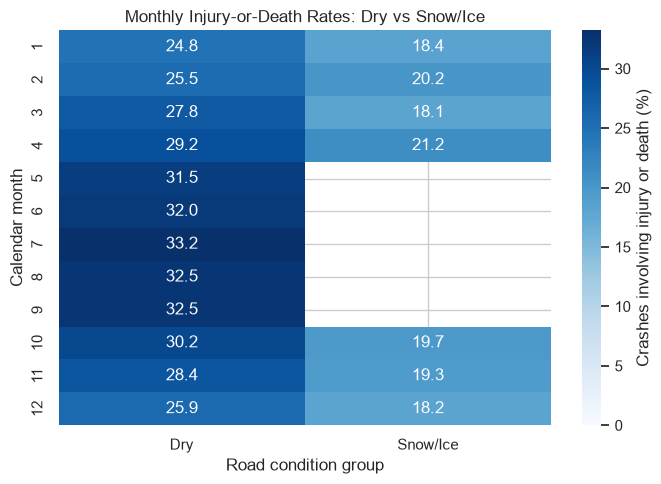

Number of crashes behind each month/group cell:


Surface_Group,Dry,Snow/Ice
Month,,
1,13490,16510
2,15307,12828
3,16814,5661
4,17389,1681
5,24947,2
6,26688,6
7,27479,1
8,27188,3
9,27789,5


In [21]:
# Show percentages where there are at least 30 crashes in a month/group cell.
monthly_group = df.groupby(["Month", "Surface_Group"])["Injury_or_Death"].agg(
    Crashes="size", Rate="mean"
).reset_index()
monthly_group["Rate_Percent"] = monthly_group["Rate"].mul(100).where(
    monthly_group["Crashes"] >= 30
)
monthly_rates = (monthly_group.pivot(index="Month", columns="Surface_Group",
                                    values="Rate_Percent")
                 .reindex(columns=surface_order).astype(float))
plt.figure(figsize=(7, 5))
sns.heatmap(monthly_rates, annot=True, fmt=".1f", cmap="Blues", vmin=0,
            cbar_kws={"label": "Crashes involving injury or death (%)"})
plt.title("Monthly Injury-or-Death Rates: Dry vs Snow/Ice")
plt.xlabel("Road condition group")
plt.ylabel("Calendar month")
plt.tight_layout()
plt.show()
print("Number of crashes behind each month/group cell:")
display(month_surface)

Dry’s injury-or-death percentage rises from 24.8% in January to a peak of 33.2% in July, then falls to 25.9% in December. Snow/Ice varies between 18.1% and 21.2% in the months shown and stays below Dry; May–September percentages are hidden because there are too few Snow/Ice crashes.

**Question 4: Does the mix of crash severity differ across road surfaces?**

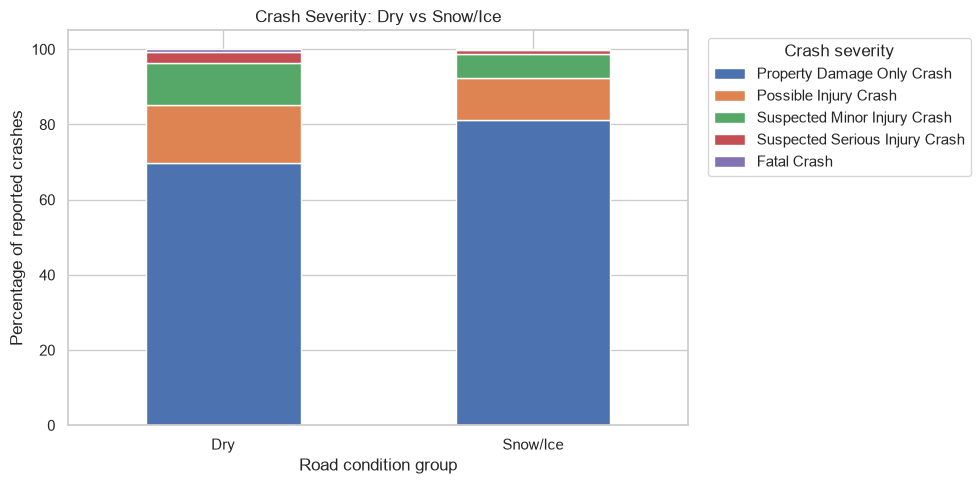

Crash Severity,Property Damage Only Crash,Possible Injury Crash,Suspected Minor Injury Crash,Suspected Serious Injury Crash,Fatal Crash
Surface_Group,,,,,
Dry,69.9,15.4,11.1,2.9,0.7
Snow/Ice,81.1,11.2,6.4,1.1,0.3


In [22]:
# Compare the mix of severity outcomes between Dry and Snow/Ice.
severity_mix = pd.crosstab(df["Surface_Group"], df["Crash Severity"],
                           normalize="index").reindex(index=surface_order,
                                                         columns=severity_order) * 100
ax = severity_mix.plot(kind="bar", stacked=True, figsize=(10, 5), rot=0)
ax.set(xlabel="Road condition group", ylabel="Percentage of reported crashes",
       title="Crash Severity: Dry vs Snow/Ice")
ax.legend(title="Crash severity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(severity_mix.round(1))

Snow/Ice has a higher percentage of property-damage-only crashes than Dry (81.1% vs. 69.9%), while Dry has higher percentages in every injury category and in fatal crashes.

**Question 5: Do other reported crash factors differ across road surfaces?**

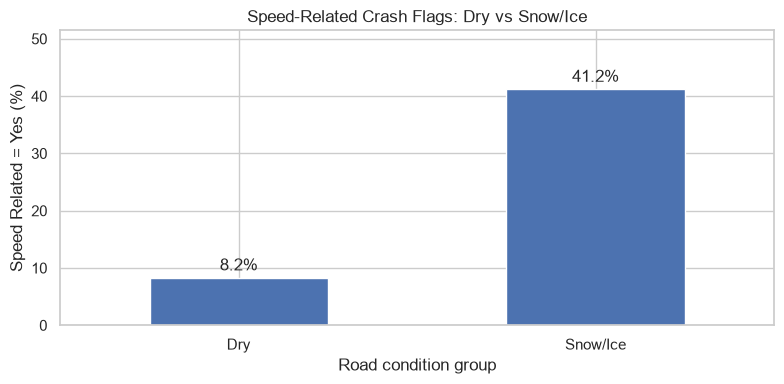

,Speed_Related_Percent
Surface_Group,
Dry,8.2
Snow/Ice,41.2


In [23]:
# Compare the percentage of crashes flagged as speed related in each group.
speed_rates = (df.groupby("Surface_Group")["Speed Related"]
               .apply(lambda x: x.eq("Yes").mean() * 100).reindex(surface_order))
ax = speed_rates.plot(kind="bar", figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(xlabel="Road condition group", ylabel="Speed Related = Yes (%)",
       title="Speed-Related Crash Flags: Dry vs Snow/Ice")
ax.set_ylim(0, speed_rates.max() * 1.25)
plt.tight_layout()
plt.show()
display(speed_rates.round(1).to_frame("Speed_Related_Percent"))

Snow/Ice has a higher percentage of crashes reported as speed-related than Dry (41.2% vs. 8.2%). However, this does not mean vehicles were traveling faster on Snow/Ice, because the data do not include actual driving speeds.

## 5. Readiness

This data can be used to compare the number of crashes, proportion of crashes involving injury or death, severity and proportion of speed related crashes between Dry and Snow/Ice. This data covers all months across 2020-2025.

Before performing statistical analysis, it is important to consider any issues with missing data in the comparison. The assumptions of the planned tests and how to account for seasonal differences should also be considered. As some months within Snow/Ice have very few crashes, consideration should be made to ensure that there are sufficient numbers of observations in each group within each month.

I will perform a 2-sided permutation test to compare the pproportion of crashes involving injury or death, and Bootstrap Confidence Intervals to estimate the difference and ratio in proportions. This analysis will examine the association between road conditions and injury-or-death outcomes among reported crashes. However, we cannot infer causation in differences in injuries due to road conditions.

## 6. Dataset-specific questions

**Question 1: Is Dry’s injury-or-death percentage still higher than Snow/Ice’s when comparing only winter months (December–February)?**

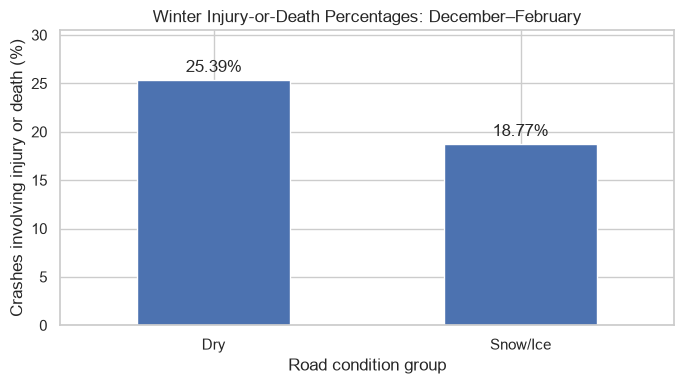

,Injury_or_Death_Percent
Surface_Group,
Dry,25.39
Snow/Ice,18.77


In [24]:
winter_df = df[df["Month"].isin([12, 1, 2])]

winter_rates = (
    winter_df.groupby("Surface_Group")["Injury_or_Death"]
    .mean().mul(100)
    .reindex(["Dry", "Snow/Ice"])
)

ax = winter_rates.plot(kind="bar", figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set(
    xlabel="Road condition group",
    ylabel="Crashes involving injury or death (%)",
    title="Winter Injury-or-Death Percentages: December–February"
)
ax.set_ylim(0, winter_rates.max() * 1.2)
plt.tight_layout()
plt.show()

display(winter_rates.round(2).to_frame("Injury_or_Death_Percent"))

Yes. During December–February, Dry still has a higher injury-or-death percentage than Snow/Ice (25.39% vs. 18.77%), a difference of 6.62 percentage points.

**Question 2: Do Dry and Snow/Ice differ in the percentage of serious-injury or fatal crashes?**

,Crashes,Serious_or_Fatal_Crashes,Rate,Rate_Percent
Surface_Group,,,,
Dry,260080,9443,0.036,3.631
Snow/Ice,65179,853,0.013,1.309


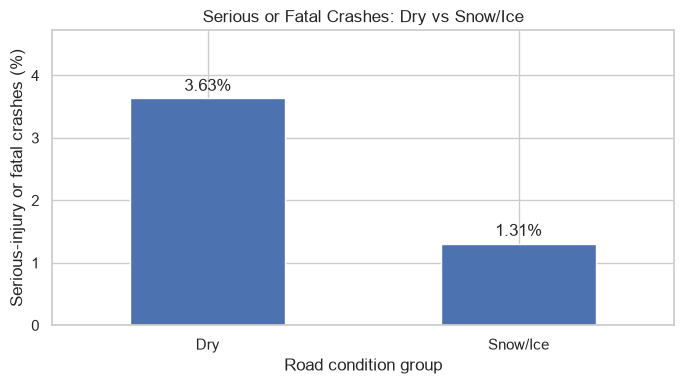

In [25]:
# Another DESCRIPTIVE outcome; no extra hypothesis test.
df["Serious_or_Fatal"] = df["Crash Severity"].isin(
    ["Suspected Serious Injury Crash", "Fatal Crash"]
)
serious_rates = (df.groupby("Surface_Group")["Serious_or_Fatal"]
                 .agg(Crashes="size", Serious_or_Fatal_Crashes="sum", Rate="mean")
                 .reindex(surface_order))
serious_rates["Rate_Percent"] = serious_rates["Rate"] * 100
display(serious_rates.round(3))
ax = serious_rates["Rate_Percent"].plot(kind="bar", figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set(xlabel="Road condition group", ylabel="Serious-injury or fatal crashes (%)",
       title="Serious or Fatal Crashes: Dry vs Snow/Ice")
ax.set_ylim(0, serious_rates["Rate_Percent"].max() * 1.3)
plt.tight_layout()
plt.show()

Serious-injury or fatal crashes account for 3.63% of Dry crashes and 1.31% of Snow/Ice crashes, a difference of 2.32 percentage points.

**Question 3: Is the injury-or-death percentage higher for Dry than Snow/Ice in both speed-related and non-speed-related crashes?**

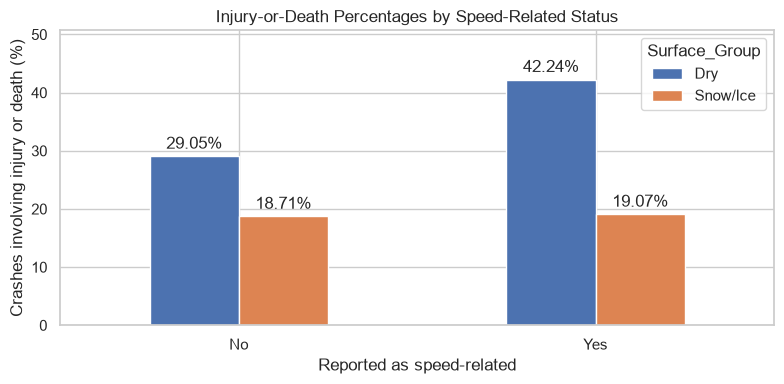

Surface_Group,Dry,Snow/Ice
Speed Related,,
No,29.05,18.71
Yes,42.24,19.07


In [26]:
speed_injury_rates = (
    df.groupby(["Speed Related", "Surface_Group"])["Injury_or_Death"]
    .mean().mul(100).unstack("Surface_Group")
    .reindex(index=["No", "Yes"], columns=["Dry", "Snow/Ice"])
)

ax = speed_injury_rates.plot(kind="bar", figsize=(8, 4), rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

ax.set(
    xlabel="Reported as speed-related",
    ylabel="Crashes involving injury or death (%)",
    title="Injury-or-Death Percentages by Speed-Related Status"
)
ax.set_ylim(0, speed_injury_rates.max().max() * 1.2)
plt.tight_layout()
plt.show()

display(speed_injury_rates.round(2))

Yes. Dry has a higher injury-or-death percentage in both speed-related crashes (42.24% vs. 19.07%) and non-speed-related crashes (29.05% vs. 18.71%). The gap is larger among speed-related crashes.

**Question 4: Does the difference in injury-or-death percentages between Dry and Snow/Ice change between daytime (6 a.m.–6 p.m.) and nighttime (6 p.m.–6 a.m.)?**

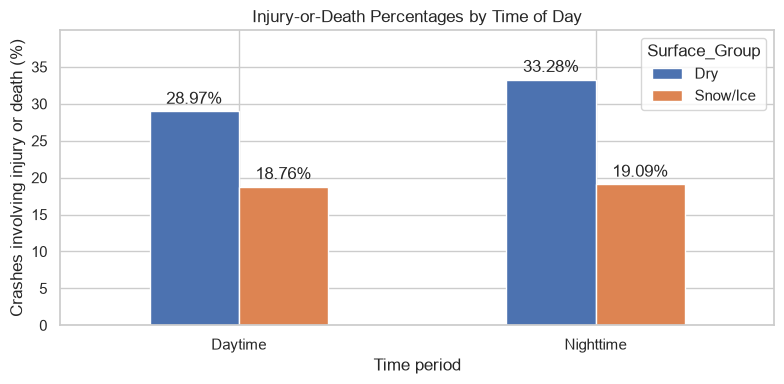

Surface_Group,Dry,Snow/Ice,Difference_pp
Time_Period,,,
Daytime,28.97,18.76,10.21
Nighttime,33.28,19.09,14.19


In [27]:
time_df = df.copy()
time_df["Time_Period"] = np.where(
    time_df["Crash_Date"].dt.hour.between(6, 17),
    "Daytime",
    "Nighttime"
)

time_rates = (
    time_df.groupby(["Time_Period", "Surface_Group"])["Injury_or_Death"]
    .mean().mul(100).unstack("Surface_Group")
    .reindex(index=["Daytime", "Nighttime"], columns=["Dry", "Snow/Ice"])
)

ax = time_rates.plot(kind="bar", figsize=(8, 4), rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

ax.set(
    xlabel="Time period",
    ylabel="Crashes involving injury or death (%)",
    title="Injury-or-Death Percentages by Time of Day"
)
ax.set_ylim(0, time_rates.max().max() * 1.2)
plt.tight_layout()
plt.show()

time_results = time_rates.copy()
time_results["Difference_pp"] = time_results["Dry"] - time_results["Snow/Ice"]
display(time_results.round(2))

Dry has a higher injury-or-death percentage during both daytime (28.97% vs. 18.76%) and nighttime (33.28% vs. 19.09%). The gap increases from 10.21 percentage points during daytime to 14.19 at night. These periods are based on clock time, not actual lighting conditions.

## Reflection

The hardest part for me was deciding how to compare the two groups fairly. Dry crashes happened throughout the year, while Snow/Ice crashes mostly happened in colder months. I compared only December through February to see whether the same pattern remained. Dry still had a higher injury-or-death percentage, but the gap was smaller than in the full-year comparison.

AI helped me with the Python code and explanations. But some suggestions did not fit my data. For example, it suggested comparing rear-end, head-on, and rollover crashes. I checked the columns and found that crash type was not included, so I could not use that question.

I now understand how to calculate injury-or-death percentages and compare Dry with Snow/Ice. I can also read the tables and explain the main differences more clearly.

I spent about 5 hours on this work. I still need to figure out how to handle seasonal differences in my final analysis, since most Snow/Ice crashes happened in colder months.